In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DATA_DIR = Path(os.environ["SOURCE_DATA_DIR"])
OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])


In [ ]:
import sys
sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.clustering import load_scene_patterns
from analysis.trace_plots import (
    plot_scene_clusters,
    plot_scene_cluster_panels,
    CLUSTER_COLORS,
    default_background_dir,
)

In [ ]:
# Plot config — edit to taste.
# Palette/marker constants and the plotting function now live in
# analysis/trace_plots.py so the rendering logic is in one importable place.

# Color each trace by its cluster ("cluster") or by clip outcome
# ("outcome": green = completed, red = death).
COLOR_BY = "cluster"

# Scene background PNGs are drawn under the traces when a matching
# <scene_id>.png exists in this dir; otherwise plots fall back to a plain
# y-flipped axis. These images don't ship with the dataset and must be
# generated separately (see mario.scenes/code/deprecated/make_images/).
# Set BACKGROUND_DIR = None to disable the overlay entirely.
BACKGROUND_DIR = default_background_dir(SOURCE_DATA_DIR)

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_summary.png


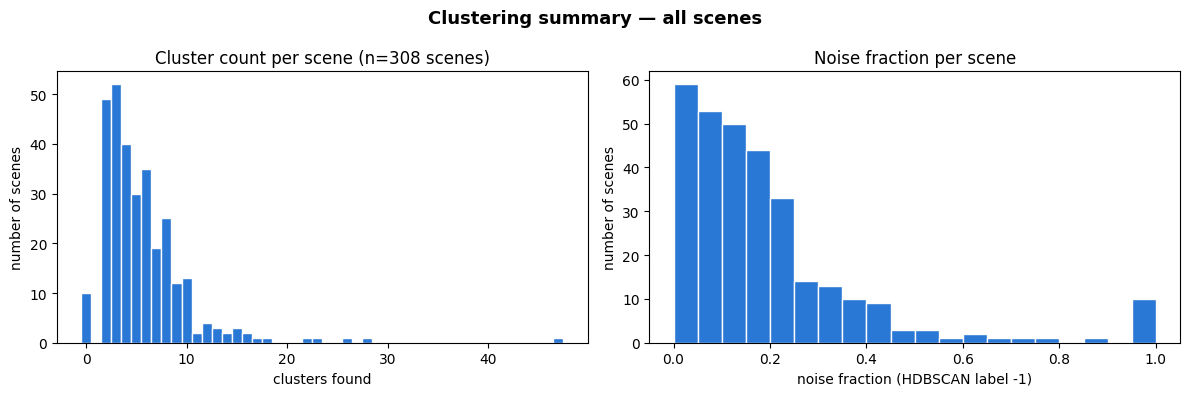

In [4]:
# --- Summary across all clustered scenes: cluster count & noise fraction ---
cluster_files = sorted((OUTPUT_DATA_DIR / "clusters").glob("*_clusters.json"))

scene_ids, n_clusters_list, noise_frac_list = [], [], []
for f in cluster_files:
    result = json.loads(f.read_text())
    labels = result["labels"]
    n_found = len(set(l for l in labels if l != -1))
    noise_frac = labels.count(-1) / len(labels) if labels else 0.0
    scene_ids.append(result["scene"])
    n_clusters_list.append(n_found)
    noise_frac_list.append(noise_frac)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(n_clusters_list, bins=range(0, max(n_clusters_list) + 2),
             color=CLUSTER_COLORS[0], edgecolor="#fcfcfb", align="left")
axes[0].set_xlabel("clusters found")
axes[0].set_ylabel("number of scenes")
axes[0].set_title(f"Cluster count per scene (n={len(scene_ids)} scenes)")

axes[1].hist(noise_frac_list, bins=20, color=CLUSTER_COLORS[0], edgecolor="#fcfcfb")
axes[1].set_xlabel("noise fraction (HDBSCAN label -1)")
axes[1].set_ylabel("number of scenes")
axes[1].set_title("Noise fraction per scene")

fig.suptitle("Clustering summary — all scenes", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_summary.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


In [5]:
# --- Detail plots: trajectories colored by cluster, for a handful of example scenes ---
# Edit this list to inspect other scenes (must have a matching <scene_id>_clusters.json).
SCENES_TO_PLOT = [scene_ids[i] for i in np.linspace(0, len(scene_ids) - 1, 4).astype(int)]
print("Plotting detail for:", SCENES_TO_PLOT)


Plotting detail for: ['w1l1s0', 'w3l3s5', 'w6l2s16', 'w8l3s9']


In [ ]:
# plot_scene_clusters now lives in analysis/trace_plots.py (imported above).
for scene_id in SCENES_TO_PLOT:
    plot_scene_clusters(
        scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
        color_by=COLOR_BY, background_dir=BACKGROUND_DIR,
    )

In [ ]:
# --- Per-cluster panels: one subplot per cluster for a scene, all in one image ---
# Splits a scene's traces so each cluster gets its own panel (shared axes),
# making individual cluster shapes easy to read. Saves
# figure_clustering_<scene>_panels.png. Edit SCENES_TO_PLOT above to pick scenes.
for scene_id in SCENES_TO_PLOT:
    plot_scene_cluster_panels(
        scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
        background_dir=BACKGROUND_DIR,
    )

In [7]:
# --- Cluster stats by scene category (pattern tag) ---
# scenes_mastersheet.csv tags each scene with one or more design-pattern labels
# (e.g. "2-Horde", "Gap stair valley"); a scene can carry several tags at once,
# so it contributes to each of its categories below (see analysis/clustering.py
# load_scene_patterns and source_data/CONTENT.md).
patterns_long = load_scene_patterns(SOURCE_DATA_DIR)

scene_stats = pd.DataFrame({
    "scene_id": scene_ids,
    "n_clusters": n_clusters_list,
    "noise_frac": noise_frac_list,
})
category_stats = patterns_long.merge(scene_stats, on="scene_id", how="inner")
print(f"{category_stats['pattern'].nunique()} categories, "
      f"{category_stats['scene_id'].nunique()} scenes with a cluster result and a category tag")


27 categories, 305 scenes with a cluster result and a category tag


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_by_category.png


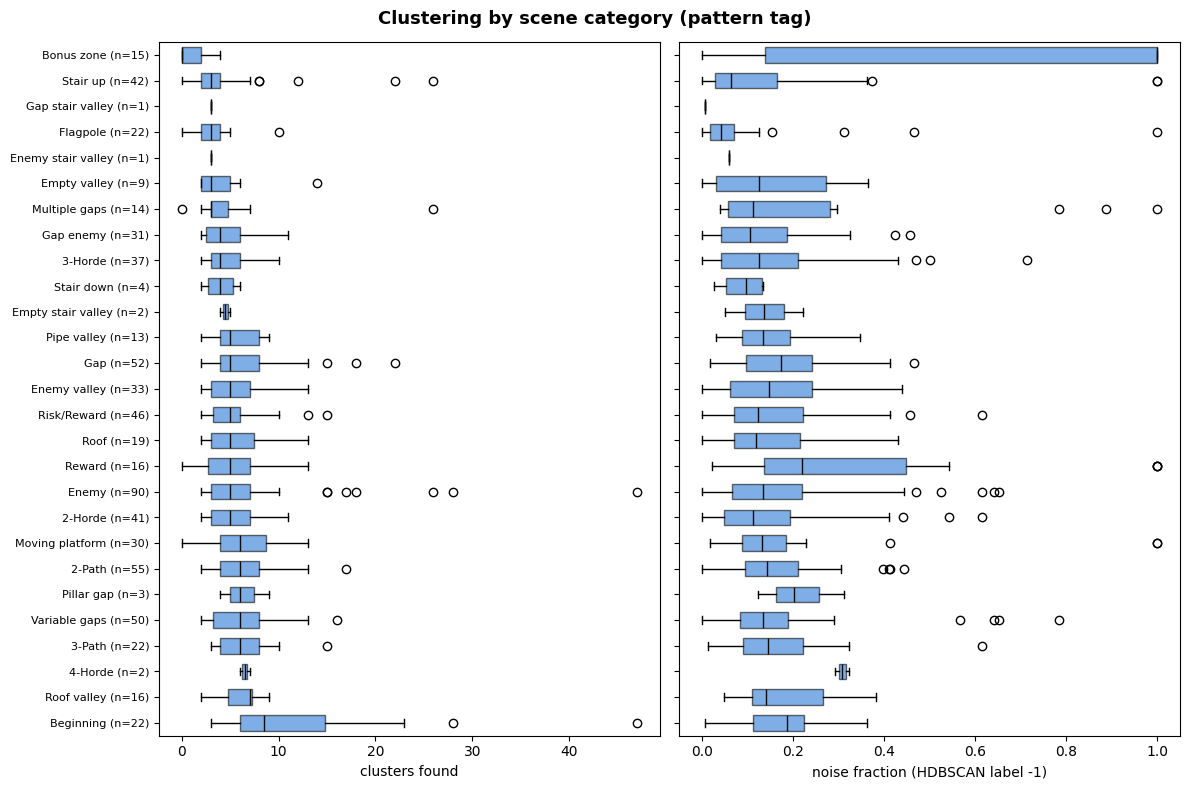

In [8]:
order = (category_stats.groupby("pattern")["n_clusters"].median()
         .sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

for ax, col, xlabel in zip(
    axes,
    ["n_clusters", "noise_frac"],
    ["clusters found", "noise fraction (HDBSCAN label -1)"],
):
    data = [category_stats.loc[category_stats["pattern"] == cat, col] for cat in order]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
                     medianprops={"color": "#0b0b0b"})
    for box in bp["boxes"]:
        box.set(facecolor=CLUSTER_COLORS[0], alpha=0.6, edgecolor="#0b0b0b")
    ax.set_xlabel(xlabel)

axes[0].set_yticks(range(1, len(order) + 1))
n_scenes_per_cat = category_stats.groupby("pattern")["scene_id"].nunique()
axes[0].set_yticklabels([f"{cat} (n={n_scenes_per_cat[cat]})" for cat in order], fontsize=8)

fig.suptitle("Clustering by scene category (pattern tag)", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_by_category.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


In [ ]:
# --- Detail plots: one small-multiples figure per category, one subplot per scene ---
# Edit this list to inspect other categories (must be a column in scenes_mastersheet.csv).
CATEGORIES_TO_PLOT = ["Gap stair valley", "2-Horde", "Flagpole"]
MAX_SCENES_PER_CATEGORY = 6  # cap so the grid stays legible; edit freely


def plot_category_grid(category):
    scenes_in_cat = sorted(patterns_long.loc[patterns_long["pattern"] == category, "scene_id"].unique())
    if not scenes_in_cat:
        print(f"No scenes tagged '{category}', skipping.")
        return
    scenes_in_cat = scenes_in_cat[:MAX_SCENES_PER_CATEGORY]

    cols = min(3, len(scenes_in_cat))
    rows = (len(scenes_in_cat) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows), squeeze=False)

    for i, scene_id in enumerate(scenes_in_cat):
        ax = axes[i // cols][i % cols]
        plot_scene_clusters(
            scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR, ax=ax,
            color_by=COLOR_BY, background_dir=BACKGROUND_DIR,
            title_fontsize=9, legend_fontsize=6,
        )
    for i in range(len(scenes_in_cat), rows * cols):
        axes[i // cols][i % cols].axis("off")

    fig.suptitle(f"Scene category: {category}", fontsize=13, fontweight="bold")
    fig.tight_layout()

    slug = category.lower().replace(" ", "_").replace("/", "-")
    out_path = OUTPUT_DATA_DIR / "clusters" / f"figure_clustering_category_{slug}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved -> {out_path}")
    plt.show()


for category in CATEGORIES_TO_PLOT:
    plot_category_grid(category)